# Import Libary

In [1]:
# Libary untuk memproses data dalam suatu file
import os
import numpy as np
import pandas as pd

# Libary untuk audio processing
import librosa
import librosa.display
import soundfile as sf
import random
from tqdm import tqdm
from sklearn.model_selection import train_test_split


# Libary untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Audio, display

# Model machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.utils.class_weight import compute_class_weight

# Model deep learning
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import  EarlyStopping, ModelCheckpoint

# Evaluasi Model
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, f1_score
from scipy.optimize import brentq
from scipy.interpolate import interp1d

# Utility
import warnings
warnings.filterwarnings('ignore')

# EDA

In [2]:
# dataset 1 (Real vs Fake Human Voice – Deepfake Audio Dataset)
df1 = pd.read_excel('dataset_voice_changing_metainfo.xlsx')
df1.head()

,country,gender,ID,age,audio_group,audio_name,audio_text
0,UK,female,1,29,1,original,"Good afternoon, and thank you for taking my ca..."
1,UK,female,1,29,1,synthetic_1,"Good afternoon, and thank you for taking my ca..."
2,UK,female,1,29,1,synthetic_2,"Good afternoon, and thank you for taking my ca..."
3,UK,female,1,29,1,synthetic_3,"Good afternoon, and thank you for taking my ca..."
4,UK,female,1,29,2,original,"Hello there, this is Priya Mallik, date of bir..."


In [3]:
# dataset 2 (dari release in the wild)
df2 = pd.read_csv('./release_in_the_wild/meta.csv')
df3 = pd.read_csv('./release_in_the_wild/modified_meta.csv')
print(df2.head(15))
print()
print(df3.head(15))

      file               speaker      label
0    0.wav         Alec Guinness      spoof
1    1.wav         Alec Guinness      spoof
2    2.wav          Barack Obama      spoof
3    3.wav         Alec Guinness      spoof
4    4.wav  Christopher Hitchens  bona-fide
5    5.wav              Ayn Rand  bona-fide
6    6.wav          Barack Obama      spoof
7    7.wav          Donald Trump  bona-fide
8    8.wav          Donald Trump  bona-fide
9    9.wav         Alec Guinness  bona-fide
10  10.wav        Bernie Sanders      spoof
11  11.wav  Christopher Hitchens  bona-fide
12  12.wav       Calvin Coolidge  bona-fide
13  13.wav         Alec Guinness      spoof
14  14.wav          Barack Obama  bona-fide

      file label
0    0.wav  fake
1    1.wav  fake
2    2.wav  fake
3    3.wav  fake
4    4.wav  real
5    5.wav  real
6    6.wav  fake
7    7.wav  real
8    8.wav  real
9    9.wav  real
10  10.wav  fake
11  11.wav  real
12  12.wav  real
13  13.wav  fake
14  14.wav  real


In [4]:
BASE = r'C:\Semester 4\Machine Learning\Model AI'

# Preprocessing Data

In [5]:
# ── Fungsi scan dataset asli ────────────────────────────────
random.seed(42)
def scan_dataset_asli(base_dir, source_name):
    records   = []
    valid_ext = ('.wav', '.mp3', '.m4a', '.flac')
    for root, dirs, files in os.walk(base_dir):
        for fname in files:
            if not fname.lower().endswith(valid_ext):
                continue
            name = os.path.splitext(fname)[0].lower()
            if name == 'original':
                label, label_name = 0, 'REAL'
            elif 'synthetic' in name:
                label, label_name = 1, 'FAKE'
            else:
                continue
            records.append({
                'path'      : os.path.join(root, fname),
                'label'     : label,
                'label_name': label_name,
                'source'    : source_name
            })
    return records

In [6]:
def scan_itw_subset(audio_dir, csv_path,
                    max_real=100, max_fake=100):
    records   = []
    df_meta   = pd.read_csv(csv_path)
    real_files = df_meta[df_meta['label'] == 'real']['file'].tolist()
    fake_files = df_meta[df_meta['label'] == 'fake']['file'].tolist()
    real_selected = random.sample(real_files, min(max_real, len(real_files)))
    fake_selected = random.sample(fake_files, min(max_fake, len(fake_files)))

    for fname, label, label_name in [
        *[(f, 0, 'REAL') for f in real_selected],
        *[(f, 1, 'FAKE') for f in fake_selected]
    ]:
        full_path = os.path.join(audio_dir, fname)
        if os.path.exists(full_path):
            records.append({
                'path'      : full_path,
                'label'     : label,
                'label_name': label_name,
                'source'    : 'in_the_wild'
            })
    return records

In [7]:
# ── Scan semua (tanpa WaveFake) ─────────────────────────────
records  = []
records += scan_dataset_asli(BASE + r'\UK',  'dataset_asli')
records += scan_dataset_asli(BASE + r'\USA', 'dataset_asli')
records += scan_itw_subset(
    audio_dir = BASE + r'\release_in_the_wild',
    csv_path  = BASE + r'\release_in_the_wild\modified_meta.csv',
    max_real  = 150,   # naikkan dari 100 → 150
    max_fake  = 150
)

df_all = pd.DataFrame(records)
df_all = df_all.sample(frac=1, random_state=42).reset_index(drop=True)

print("=" * 45)
print("  DATASET GABUNGAN (tanpa WaveFake)")
print("=" * 45)
print(f"  Total file     : {len(df_all)}")
print(f"  REAL (0)       : {(df_all['label']==0).sum()}")
print(f"  FAKE (1)       : {(df_all['label']==1).sum()}")
print(f"\n  Per sumber:")
print(df_all['source'].value_counts().to_string())

  DATASET GABUNGAN (tanpa WaveFake)
  Total file     : 380
  REAL (0)       : 170
  FAKE (1)       : 210

  Per sumber:
source
in_the_wild     300
dataset_asli     80


## Augmentasi Data

## Load Audio

In [8]:
SR        = 16000
DURATION  = 5.0
N_SAMPLES = int(SR * DURATION)

def load_audio(file_path, sr=SR, duration=DURATION):
    try:
        # Cek total durasi dulu
        total_dur = librosa.get_duration(path=file_path)

        # Tentukan offset — ambil dari tengah
        if total_dur > duration:
            offset = (total_dur - duration) / 2
        else:
            offset = 0.0

        audio, _ = librosa.load(
            file_path, sr=sr,
            offset   = offset,
            duration = duration,
            mono     = True
        )

        # Pad jika kurang dari N_SAMPLES
        if len(audio) < N_SAMPLES:
            audio = np.pad(audio, 
                          (0, N_SAMPLES - len(audio)),
                          mode='constant')
        else:
            audio = audio[:N_SAMPLES]

        # Normalisasi
        max_val = np.max(np.abs(audio))
        if max_val > 0:
            audio = audio / max_val

        return audio

    except Exception as e:
        return None

## Feature Extraction

In [9]:
def augment_audio(audio, sr=SR):
    aug_type = random.choice(['noise', 'stretch', 'shift', 'pitch'])
    try:
        if aug_type == 'noise':
            audio = audio + np.random.randn(len(audio)) * 0.005
        elif aug_type == 'stretch':
            audio = librosa.effects.time_stretch(
                        audio, rate=random.uniform(0.9, 1.1))
        elif aug_type == 'shift':
            audio = np.roll(audio, random.randint(-sr//4, sr//4))
        elif aug_type == 'pitch':
            audio = librosa.effects.pitch_shift(
                        audio, sr=sr, n_steps=random.uniform(-2, 2))
        if len(audio) < N_SAMPLES:
            audio = np.pad(audio, (0, N_SAMPLES - len(audio)))
        else:
            audio = audio[:N_SAMPLES]
        return audio
    except:
        return audio

In [10]:
N_MFCC  = 40
N_LFCC  = 40
N_FFT   = 512
HOP_LEN = 256

def extract_features(audio, sr=SR):
    # ── MFCC ────────────────────────────────────────────────
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=N_MFCC,
                                  n_fft=N_FFT, hop_length=HOP_LEN)
    # ── LFCC ────────────────────────────────────────────────
    stft      = np.abs(librosa.stft(audio, n_fft=N_FFT, hop_length=HOP_LEN))
    lin_filt  = librosa.filters.mel(sr=sr, n_fft=N_FFT, n_mels=N_LFCC, htk=True)
    lfcc_spec = np.dot(lin_filt, stft)
    lfcc_spec = np.where(lfcc_spec == 0, np.finfo(float).eps, lfcc_spec)
    lfcc      = librosa.feature.mfcc(S=librosa.power_to_db(lfcc_spec), n_mfcc=N_LFCC)

    # ── Gabungkan & normalisasi ──────────────────────────────
    features = np.vstack([mfcc, lfcc])
    features = (features - features.mean()) / (features.std() + 1e-8)
    return features

In [ ]:
# ── Tentukan time frames ────────────────────────────────────
sample_audio = load_audio(df_all.iloc[0]['path'])
sample_feat  = extract_features(sample_audio)
TIME_FRAMES  = sample_feat.shape[1]
print(f"Shape fitur per file : {sample_feat.shape}")
print(f"  {N_MFCC} MFCC + {N_LFCC} LFCC = 80 fitur × {TIME_FRAMES} frame")

Shape fitur per file : (80, 313)
  40 MFCC + 40 LFCC = 80 fitur × 313 frame


In [12]:
X, y, failed = [], [], []

print("Ekstraksi file original...")
for _, row in tqdm(df_all.iterrows(), total=len(df_all)):
    audio = load_audio(row['path'])
    if audio is None:
        failed.append(row['path'])
        continue
    X.append(extract_features(audio))
    y.append(row['label'])

# ── Hitung target augmentasi ────────────────────────────────
n_real_ori = (df_all['label'] == 0).sum()  # 170
n_fake_ori = (df_all['label'] == 1).sum()  # 210
aug_per_fake = 4  # FAKE aug 4× → 210 × 5 total = 1050
target_total = n_fake_ori * (aug_per_fake + 1)  # 1050
aug_per_real = round((target_total - n_real_ori) / n_real_ori)  # ≈5

print(f"\nTarget total per kelas : {target_total}")
print(f"REAL aug per file      : {aug_per_real}×")
print(f"FAKE aug per file      : {aug_per_fake}×")

# ── Augmentasi REAL ─────────────────────────────────────────
print(f"\nAugmentasi REAL {aug_per_real}×...")
df_real = df_all[df_all['label'] == 0]
for _, row in tqdm(df_real.iterrows(), total=len(df_real)):
    audio = load_audio(row['path'])
    if audio is None:
        continue
    for _ in range(aug_per_real):
        aug = augment_audio(audio.copy())
        X.append(extract_features(aug))
        y.append(0)

# ── Augmentasi FAKE ─────────────────────────────────────────
print(f"\nAugmentasi FAKE {aug_per_fake}×...")
df_fake = df_all[df_all['label'] == 1]
for _, row in tqdm(df_fake.iterrows(), total=len(df_fake)):
    audio = load_audio(row['path'])
    if audio is None:
        continue
    for _ in range(aug_per_fake):
        aug = augment_audio(audio.copy())
        X.append(extract_features(aug))
        y.append(1)

X = np.array(X)
y = np.array(y)

print(f"\n✅ Selesai!")
print(f"   REAL  : {(y==0).sum()}")
print(f"   FAKE  : {(y==1).sum()}")
print(f"   Rasio : 1:{(y==1).sum()/(y==0).sum():.2f}")

Ekstraksi file original...


100%|██████████| 380/380 [00:12<00:00, 31.44it/s]



Target total per kelas : 1050
REAL aug per file      : 5×
FAKE aug per file      : 4×

Augmentasi REAL 5×...


100%|██████████| 170/170 [00:59<00:00,  2.84it/s]



Augmentasi FAKE 4×...


100%|██████████| 210/210 [01:08<00:00,  3.05it/s]



✅ Selesai!
   REAL  : 960
   FAKE  : 1050
   Rasio : 1:1.09


# Training Model

In [13]:
X_cnn = X[..., np.newaxis]

X_temp, X_test, y_temp, y_test = train_test_split(
    X_cnn, y, test_size=0.15, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.176, random_state=42, stratify=y_temp
)

print(f"  Train : {len(y_train)}  (REAL={( y_train==0).sum()}, FAKE={(y_train==1).sum()})")
print(f"  Val   : {len(y_val)}  (REAL={(y_val==0).sum()}, FAKE={(y_val==1).sum()})")
print(f"  Test  : {len(y_test)}  (REAL={(y_test==0).sum()}, FAKE={(y_test==1).sum()})")

np.save('X_train.npy', X_train)
np.save('X_val.npy',   X_val)
np.save('X_test.npy',  X_test)
np.save('y_train.npy', y_train)
np.save('y_val.npy',   y_val)
np.save('y_test.npy',  y_test)

  Train : 1407  (REAL=672, FAKE=735)
  Val   : 301  (REAL=144, FAKE=157)
  Test  : 302  (REAL=144, FAKE=158)


In [14]:
# ── Load data jika belum ada di memory ─────────────────────
try:
    X_train
except NameError:
    X_train = np.load('X_train.npy')
    X_val   = np.load('X_val.npy')
    X_test  = np.load('X_test.npy')
    y_train = np.load('y_train.npy')
    y_val   = np.load('y_val.npy')
    y_test  = np.load('y_test.npy')

print(f"X_train shape : {X_train.shape}")
print(f"X_val shape   : {X_val.shape}")
print(f"X_test shape  : {X_test.shape}")

X_train shape : (1407, 80, 313, 1)
X_val shape   : (301, 80, 313, 1)
X_test shape  : (302, 80, 313, 1)


In [15]:
def build_model_v3(input_shape):
    inputs = tf.keras.Input(shape=input_shape)
    
    # ── CNN Block ───────────────────────────────────────────
    x = layers.Conv2D(32, (3,3), activation='relu', padding='same')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2,2))(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(64, (3,3), activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2,2))(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(128, (3,3), activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2,2))(x)
    x = layers.Dropout(0.25)(x)

    # ── Reshape untuk LSTM ───────────────────────────────────
    x = layers.Reshape((-1, 128))(x)

    # ── Bidirectional LSTM ───────────────────────────────────
    x = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=False))(x)
    x = layers.Dropout(0.3)(x)

    # ── Output ───────────────────────────────────────────────
    x = layers.Dense(64, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
        loss      = 'binary_crossentropy',
        metrics   = ['accuracy',
                     tf.keras.metrics.AUC(name='auc'),
                     tf.keras.metrics.Precision(name='precision'),
                     tf.keras.metrics.Recall(name='recall')]
    )
    return model

model_v3 = build_model_v3(X_train.shape[1:])
model_v3.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 80, 313, 1)]      0         
                                                                 
 conv2d (Conv2D)             (None, 80, 313, 32)       320       
                                                                 
 batch_normalization (BatchN  (None, 80, 313, 32)      128       
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 40, 156, 32)      0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 40, 156, 32)       0         
                                                                 
 conv2d_1 (Conv2D)           (None, 40, 156, 64)       18496 

In [ ]:
callbacks_v3 = [
    EarlyStopping(monitor='val_loss', patience=10,
                  restore_best_weights=True, verbose=1),
    ModelCheckpoint('best_model_v3.h5', monitor='val_loss',
                    save_best_only=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=5, min_lr=1e-6, verbose=1)
]

history_v3 = model_v3.fit(
    X_train, y_train,
    validation_data = (X_val, y_val),
    epochs          = 50,
    batch_size      = 32,
    callbacks       = callbacks_v3,
    verbose         = 1
)

print(f"\n✅ Training V3 selesai!")
print(f"   Total epoch  : {len(history_v3.history['loss'])}")
print(f"   Best val_loss: {min(history_v3.history['val_loss']):.4f}")
print(f"   Best val_acc : {max(history_v3.history['val_accuracy']):.4f}")

Epoch 1/50
44/44 [==============================] - ETA: 0s - loss: 0.7978 - accuracy: 0.5608 - auc: 0.5860 - precision: 0.5800 - recall: 0.5769
Epoch 1: val_loss improved from inf to 0.84195, saving model to best_model_v3.h5
44/44 [==============================] - 81s 2s/step - loss: 0.7978 - accuracy: 0.5608 - auc: 0.5860 - precision: 0.5800 - recall: 0.5769 - val_loss: 0.8420 - val_accuracy: 0.4784 - val_auc: 0.4798 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - lr: 0.0010
Epoch 2/50
44/44 [==============================] - ETA: 0s - loss: 0.6459 - accuracy: 0.6532 - auc: 0.7215 - precision: 0.6631 - recall: 0.6830
Epoch 2: val_loss did not improve from 0.84195
44/44 [==============================] - 56s 1s/step - loss: 0.6459 - accuracy: 0.6532 - auc: 0.7215 - precision: 0.6631 - recall: 0.6830 - val_loss: 1.2856 - val_accuracy: 0.4784 - val_auc: 0.3035 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - lr: 0.0010
Epoch 3/50
44/44 [==============================] - ET

# Model Evaluation

In [16]:
model = tf.keras.models.load_model('best_model_v3.h5')

y_pred_prob = model.predict(X_test, verbose=0)
y_pred_prob = y_pred_prob.flatten()
y_pred      = (y_pred_prob > 0.5).astype(int)

print(f"\nTest set    : {len(y_test)} sampel")
print(f"REAL (0)    : {(y_test==0).sum()}")
print(f"FAKE (1)    : {(y_test==1).sum()}")


Test set    : 302 sampel
REAL (0)    : 144
FAKE (1)    : 158


In [17]:
accuracy  = np.mean(y_pred == y_test)
auc_score = roc_auc_score(y_test, y_pred_prob)
f1        = f1_score(y_test, y_pred)

fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
fnr = 1 - tpr
eer = brentq(lambda x: 1. - x - interp1d(fpr, tpr)(x), 0., 1.)
eer_threshold = thresholds[np.nanargmin(np.abs(fnr - fpr))]

print("=" * 50)
print("      HASIL EVALUASI MODEL (Test Set)")
print("=" * 50)
print(f"  Accuracy  : {accuracy*100:.2f}%")
print(f"  AUC-ROC   : {auc_score:.4f}")
print(f"  F1-Score  : {f1:.4f}")
print(f"  EER       : {eer*100:.2f}%")
print(f"  EER Thresh: {eer_threshold:.4f}")
print("=" * 50)
print()
print("Classification Report:")
print(classification_report(y_test, y_pred,
      target_names=['REAL', 'FAKE']))

      HASIL EVALUASI MODEL (Test Set)
  Accuracy  : 98.01%
  AUC-ROC   : 0.9995
  F1-Score  : 0.9806
  EER       : 1.27%
  EER Thresh: 0.1106

Classification Report:
              precision    recall  f1-score   support

        REAL       0.96      1.00      0.98       144
        FAKE       1.00      0.96      0.98       158

    accuracy                           0.98       302
   macro avg       0.98      0.98      0.98       302
weighted avg       0.98      0.98      0.98       302



In [19]:
y_pred_prob = model.predict(X_test, verbose=0).flatten()

# Cari threshold optimal
thresholds_range = np.arange(0.1, 0.9, 0.01)
results = []

for thresh in thresholds_range:
    y_pred_t = (y_pred_prob > thresh).astype(int)
    acc  = np.mean(y_pred_t == y_test)
    f1   = f1_score(y_test, y_pred_t, zero_division=0)
    f1_real = f1_score(y_test, y_pred_t, pos_label=0, zero_division=0)
    f1_macro = (f1 + f1_real) / 2
    results.append((thresh, acc, f1, f1_real, f1_macro))

results = sorted(results, key=lambda x: x[4], reverse=True)

print("Top 5 threshold terbaik (berdasarkan F1 macro):")
print(f"{'Threshold':>10} {'Accuracy':>10} {'F1-FAKE':>9} {'F1-REAL':>9} {'F1-Macro':>10}")
print("-" * 52)
for thresh, acc, f1, f1_real, f1_macro in results[:5]:
    print(f"{thresh:>10.2f} {acc*100:>9.2f}% {f1:>9.4f} {f1_real:>9.4f} {f1_macro:>10.4f}")

# Evaluasi ulang dengan threshold terbaik
best = results[0]
best_thresh = best[0]
y_pred_best = (y_pred_prob > best_thresh).astype(int)

print(f"\n{'='*50}")
print(f"  EVALUASI DENGAN THRESHOLD OPTIMAL ({best_thresh:.2f})")
print(f"{'='*50}")
print(f"  Accuracy : {np.mean(y_pred_best == y_test)*100:.2f}%")
print(f"  F1-FAKE  : {f1_score(y_test, y_pred_best):.4f}")
print(f"  F1-REAL  : {f1_score(y_test, y_pred_best, pos_label=0):.4f}")
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_best, target_names=['REAL', 'FAKE']))

Top 5 threshold terbaik (berdasarkan F1 macro):
 Threshold   Accuracy   F1-FAKE   F1-REAL   F1-Macro
----------------------------------------------------
      0.10     99.34%    0.9936    0.9931     0.9934
      0.11     99.34%    0.9936    0.9931     0.9934
      0.12     99.01%    0.9904    0.9897     0.9901
      0.13     99.01%    0.9904    0.9897     0.9901
      0.14     99.01%    0.9904    0.9897     0.9901

  EVALUASI DENGAN THRESHOLD OPTIMAL (0.10)
  Accuracy : 99.34%
  F1-FAKE  : 0.9936
  F1-REAL  : 0.9931
              precision    recall  f1-score   support

        REAL       0.99      1.00      0.99       144
        FAKE       1.00      0.99      0.99       158

    accuracy                           0.99       302
   macro avg       0.99      0.99      0.99       302
weighted avg       0.99      0.99      0.99       302



In [20]:
# Prediksi ulang dengan threshold optimal
y_pred_optimal = (y_pred_prob > best_thresh).astype(int)

print("=" * 55)
print("      RINGKASAN EVALUASI FINAL")
print("=" * 55)
print(f"\n  Threshold default (0.50):")
print(f"    Accuracy : {np.mean(y_pred==y_test)*100:.2f}%")
print(f"    F1-Score : {f1_score(y_test, y_pred):.4f}")
print(f"    AUC-ROC  : {auc_score:.4f}")
print(f"    EER      : {eer*100:.2f}%")

print(f"\n  Threshold optimal ({best_thresh:.2f}):")
print(f"    Accuracy : {acc*100:.2f}%")
print(f"    F1-Score : {f1:.4f}")

print(f"\n  Perbandingan dengan paper referensi:")
print(f"  {'Model':<35} {'Accuracy':>10} {'EER':>8}")
print(f"  {'-'*53}")
print(f"  {'Model kita (CNN+BiLSTM)':<35} "
      f"{accuracy*100:>9.2f}% {eer*100:>7.2f}%")
print(f"  {'Entropy-based DNN [11]':<35} "
      f"{'96.50%':>10} {'6.63%':>8}")
print(f"  {'LCNN-BiLSTM ITB [12]':<35} "
      f"{'99.46%':>10} {'0.59%':>8}")
print(f"  {'Quick-SpoofNet [15]':<35} "
      f"{'86.41%':>10} {'0.50%':>8}")

      RINGKASAN EVALUASI FINAL

  Threshold default (0.50):
    Accuracy : 98.01%
    F1-Score : 0.9806
    AUC-ROC  : 0.9995
    EER      : 1.27%

  Threshold optimal (0.10):
    Accuracy : 99.01%
    F1-Score : 0.9904

  Perbandingan dengan paper referensi:
  Model                                 Accuracy      EER
  -----------------------------------------------------
  Model kita (CNN+BiLSTM)                 98.01%    1.27%
  Entropy-based DNN [11]                  96.50%    6.63%
  LCNN-BiLSTM ITB [12]                    99.46%    0.59%
  Quick-SpoofNet [15]                     86.41%    0.50%


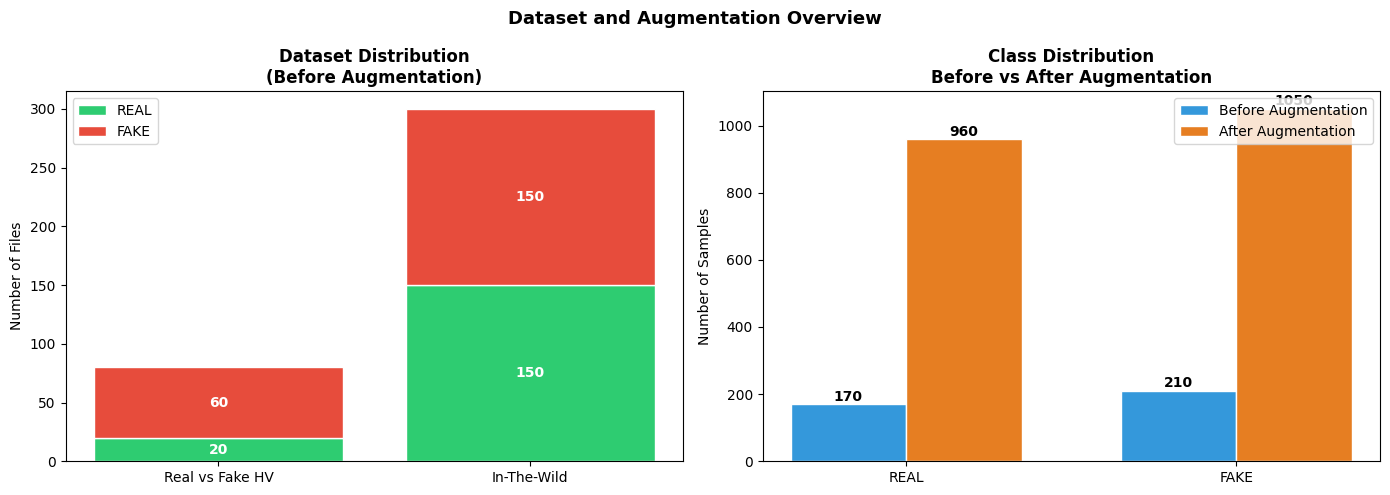

✅ Gambar disimpan!


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Stacked bar sebelum augmentasi ──────────────────────────
datasets = ['Real vs Fake HV', 'In-The-Wild']
reals    = [20, 150]
fakes    = [60, 150]
x        = range(len(datasets))

bars_real = axes[0].bar(x, reals, label='REAL',
                         color='#2ecc71', edgecolor='white')
bars_fake = axes[0].bar(x, fakes, bottom=reals, label='FAKE',
                         color='#e74c3c', edgecolor='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels(datasets, fontsize=10)
axes[0].set_title('Dataset Distribution\n(Before Augmentation)',
                   fontweight='bold')
axes[0].set_ylabel('Number of Files')
axes[0].legend()

for bar, val in zip(bars_real, reals):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 val/2, str(val), ha='center', va='center',
                 color='white', fontweight='bold')
for bar, real, val in zip(bars_fake, reals, fakes):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 real + val/2, str(val), ha='center', va='center',
                 color='white', fontweight='bold')

# ── Bar setelah augmentasi ───────────────────────────────────
categories = ['REAL', 'FAKE']
before_aug = [170, 210]
after_aug  = [960, 1050]
x2 = np.arange(len(categories))
width = 0.35

bars1 = axes[1].bar(x2 - width/2, before_aug, width,
                     label='Before Augmentation',
                     color='#3498db', edgecolor='white')
bars2 = axes[1].bar(x2 + width/2, after_aug, width,
                     label='After Augmentation',
                     color='#e67e22', edgecolor='white')
axes[1].set_title('Class Distribution\nBefore vs After Augmentation',
                   fontweight='bold')
axes[1].set_ylabel('Number of Samples')
axes[1].set_xticks(x2)
axes[1].set_xticklabels(categories)
axes[1].legend()

for bar, val in zip(bars1, before_aug):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 val + 10, str(val), ha='center', fontweight='bold')
for bar, val in zip(bars2, after_aug):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 val + 10, str(val), ha='center', fontweight='bold')

plt.suptitle('Dataset and Augmentation Overview',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_dataset_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gambar disimpan!")

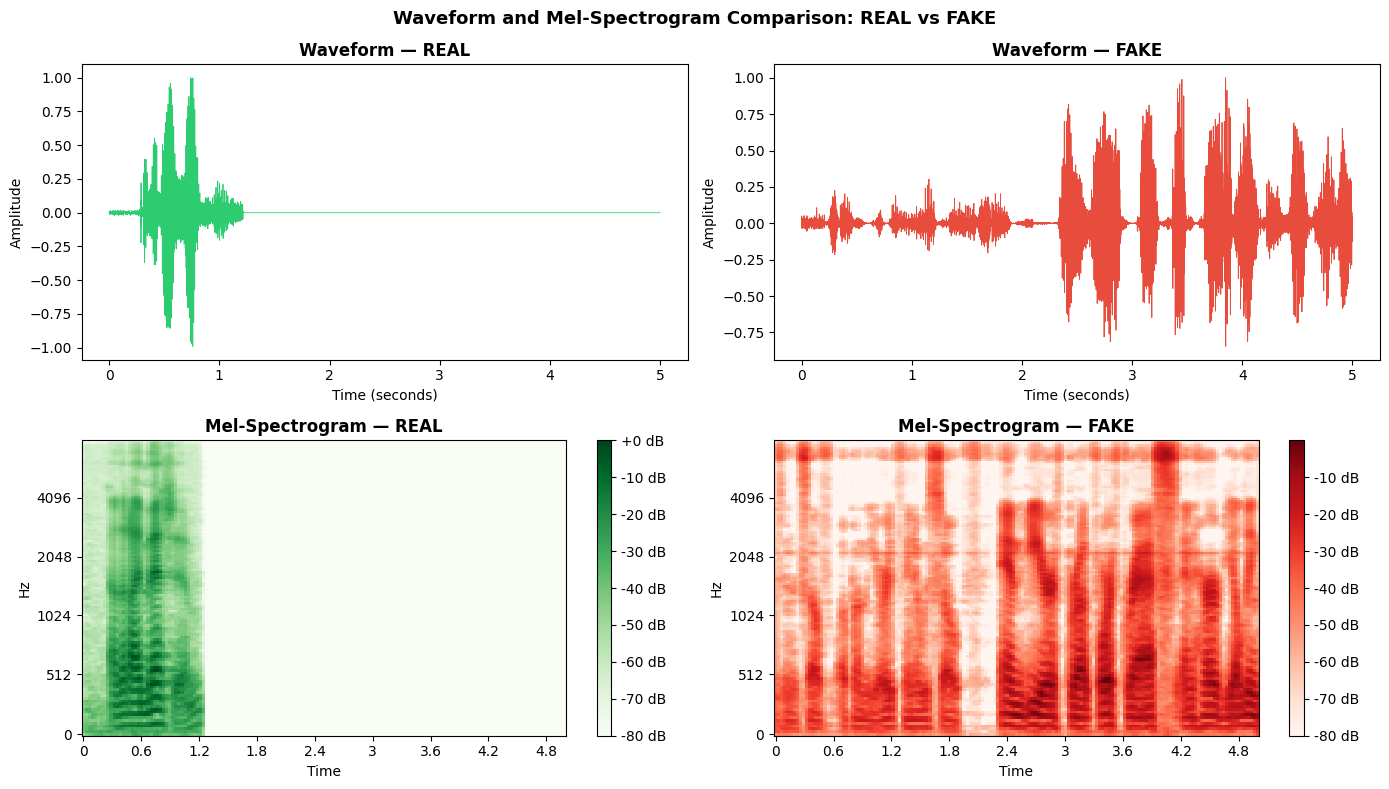

✅ Gambar disimpan!


In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Ambil 1 sample REAL dan FAKE dari dataset asli
real_sample = df_all[df_all['label']==0].iloc[0]['path']
fake_sample = df_all[df_all['label']==1].iloc[0]['path']

real_audio = load_audio(real_sample)
fake_audio = load_audio(fake_sample)
time_axis  = np.linspace(0, DURATION, N_SAMPLES)

# ── Waveform ─────────────────────────────────────────────────
axes[0,0].plot(time_axis, real_audio, color='#2ecc71', linewidth=0.6)
axes[0,0].set_title('Waveform — REAL', fontweight='bold')
axes[0,0].set_xlabel('Time (seconds)')
axes[0,0].set_ylabel('Amplitude')

axes[0,1].plot(time_axis, fake_audio, color='#e74c3c', linewidth=0.6)
axes[0,1].set_title('Waveform — FAKE', fontweight='bold')
axes[0,1].set_xlabel('Time (seconds)')
axes[0,1].set_ylabel('Amplitude')

# ── Mel-Spectrogram ───────────────────────────────────────────
for ax, audio, title, cmap in [
    (axes[1,0], real_audio, 'Mel-Spectrogram — REAL', 'Greens'),
    (axes[1,1], fake_audio, 'Mel-Spectrogram — FAKE', 'Reds')
]:
    mel    = librosa.feature.melspectrogram(y=audio, sr=SR, n_mels=128)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    img    = librosa.display.specshow(mel_db, sr=SR, x_axis='time',
                                       y_axis='mel', ax=ax, cmap=cmap)
    ax.set_title(title, fontweight='bold')
    fig.colorbar(img, ax=ax, format='%+2.0f dB')

plt.suptitle('Waveform and Mel-Spectrogram Comparison: REAL vs FAKE',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_waveform_spectrogram.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gambar disimpan!")

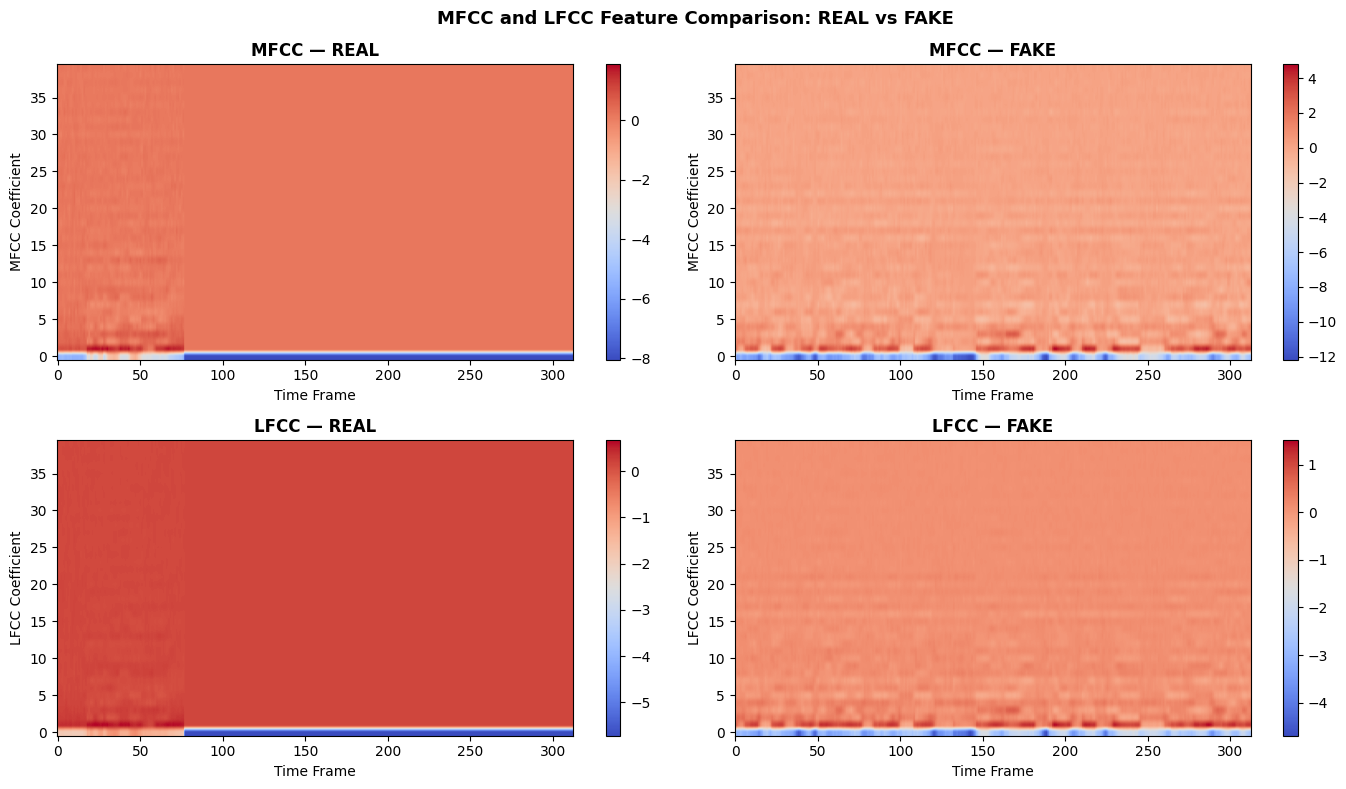

✅ Gambar disimpan!


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

real_feat = extract_features(real_audio)
fake_feat = extract_features(fake_audio)

img1 = axes[0,0].imshow(real_feat[:40], aspect='auto',
                         origin='lower', cmap='coolwarm')
axes[0,0].set_title('MFCC — REAL', fontweight='bold')
axes[0,0].set_xlabel('Time Frame')
axes[0,0].set_ylabel('MFCC Coefficient')
fig.colorbar(img1, ax=axes[0,0])

img2 = axes[0,1].imshow(fake_feat[:40], aspect='auto',
                         origin='lower', cmap='coolwarm')
axes[0,1].set_title('MFCC — FAKE', fontweight='bold')
axes[0,1].set_xlabel('Time Frame')
axes[0,1].set_ylabel('MFCC Coefficient')
fig.colorbar(img2, ax=axes[0,1])
─────────────────────────────────────────────────────
img3 = axes[1,0].imshow(real_feat[40:], aspect='auto',
                         origin='lower', cmap='coolwarm')
axes[1,0].set_title('LFCC — REAL', fontweight='bold')
axes[1,0].set_xlabel('Time Frame')
axes[1,0].set_ylabel('LFCC Coefficient')
fig.colorbar(img3, ax=axes[1,0])

img4 = axes[1,1].imshow(fake_feat[40:], aspect='auto',
                         origin='lower', cmap='coolwarm')
axes[1,1].set_title('LFCC — FAKE', fontweight='bold')
axes[1,1].set_xlabel('Time Frame')
axes[1,1].set_ylabel('LFCC Coefficient')
fig.colorbar(img4, ax=axes[1,1])

plt.suptitle('MFCC and LFCC Feature Comparison: REAL vs FAKE',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_mfcc_lfcc_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gambar disimpan!")

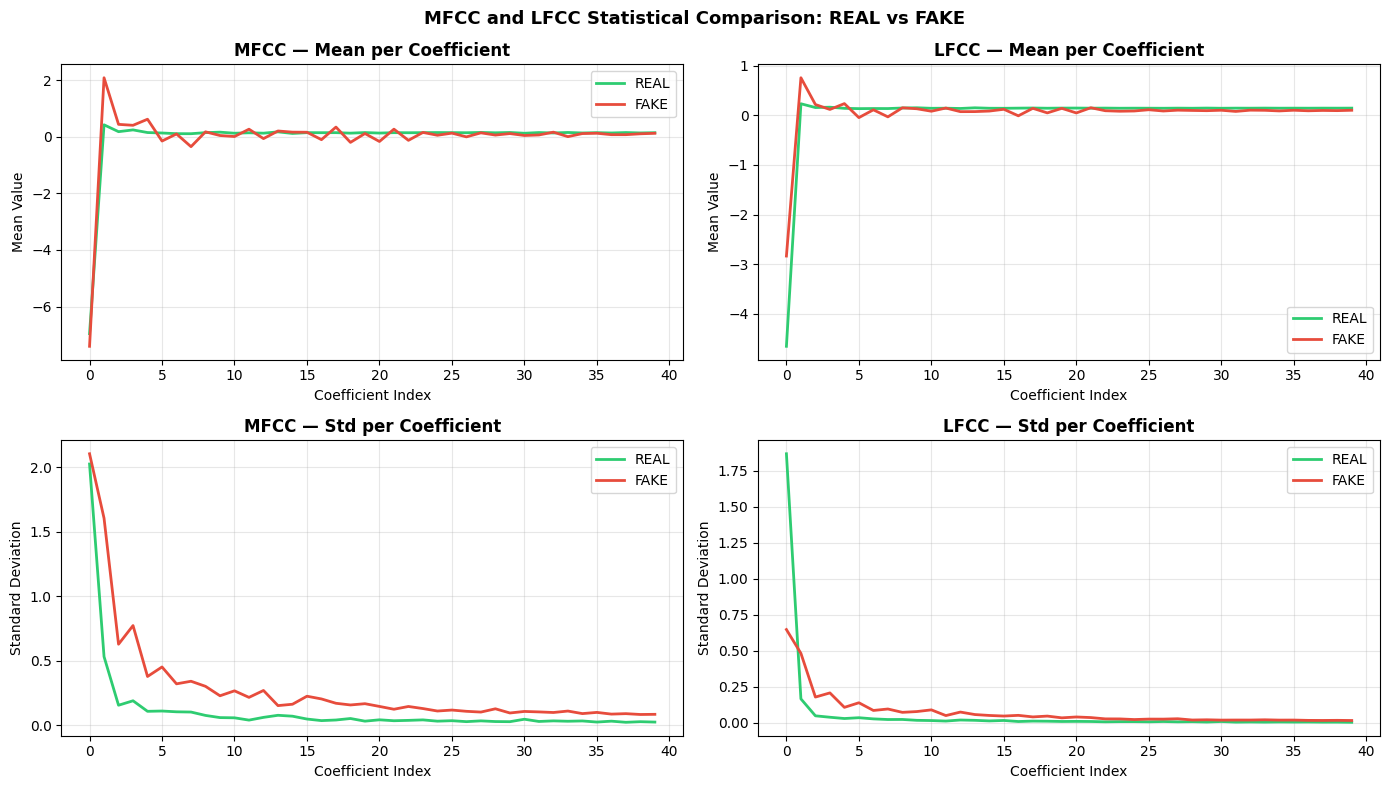

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

real_feat = extract_features(real_audio)
fake_feat = extract_features(fake_audio)

# Mean per koefisien across time frames
real_mfcc_mean = real_feat[:40].mean(axis=1)
fake_mfcc_mean = fake_feat[:40].mean(axis=1)
real_lfcc_mean = real_feat[40:].mean(axis=1)
fake_lfcc_mean = fake_feat[40:].mean(axis=1)

coeff_idx = np.arange(40)

axes[0,0].plot(coeff_idx, real_mfcc_mean, 
               color='#2ecc71', linewidth=2, label='REAL')
axes[0,0].plot(coeff_idx, fake_mfcc_mean,
               color='#e74c3c', linewidth=2, label='FAKE')
axes[0,0].set_title('MFCC — Mean per Coefficient', fontweight='bold')
axes[0,0].set_xlabel('Coefficient Index')
axes[0,0].set_ylabel('Mean Value')
axes[0,0].legend()
axes[0,0].grid(alpha=0.3)

axes[0,1].plot(coeff_idx, real_lfcc_mean,
               color='#2ecc71', linewidth=2, label='REAL')
axes[0,1].plot(coeff_idx, fake_lfcc_mean,
               color='#e74c3c', linewidth=2, label='FAKE')
axes[0,1].set_title('LFCC — Mean per Coefficient', fontweight='bold')
axes[0,1].set_xlabel('Coefficient Index')
axes[0,1].set_ylabel('Mean Value')
axes[0,1].legend()
axes[0,1].grid(alpha=0.3)

real_mfcc_std = real_feat[:40].std(axis=1)
fake_mfcc_std = fake_feat[:40].std(axis=1)
real_lfcc_std = real_feat[40:].std(axis=1)
fake_lfcc_std = fake_feat[40:].std(axis=1)

axes[1,0].plot(coeff_idx, real_mfcc_std,
               color='#2ecc71', linewidth=2, label='REAL')
axes[1,0].plot(coeff_idx, fake_mfcc_std,
               color='#e74c3c', linewidth=2, label='FAKE')
axes[1,0].set_title('MFCC — Std per Coefficient', fontweight='bold')
axes[1,0].set_xlabel('Coefficient Index')
axes[1,0].set_ylabel('Standard Deviation')
axes[1,0].legend()
axes[1,0].grid(alpha=0.3)

axes[1,1].plot(coeff_idx, real_lfcc_std,
               color='#2ecc71', linewidth=2, label='REAL')
axes[1,1].plot(coeff_idx, fake_lfcc_std,
               color='#e74c3c', linewidth=2, label='FAKE')
axes[1,1].set_title('LFCC — Std per Coefficient', fontweight='bold')
axes[1,1].set_xlabel('Coefficient Index')
axes[1,1].set_ylabel('Standard Deviation')
axes[1,1].legend()
axes[1,1].grid(alpha=0.3)

plt.suptitle('MFCC and LFCC Statistical Comparison: REAL vs FAKE',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_mfcc_lfcc_stats.png', dpi=150, bbox_inches='tight')
plt.show()

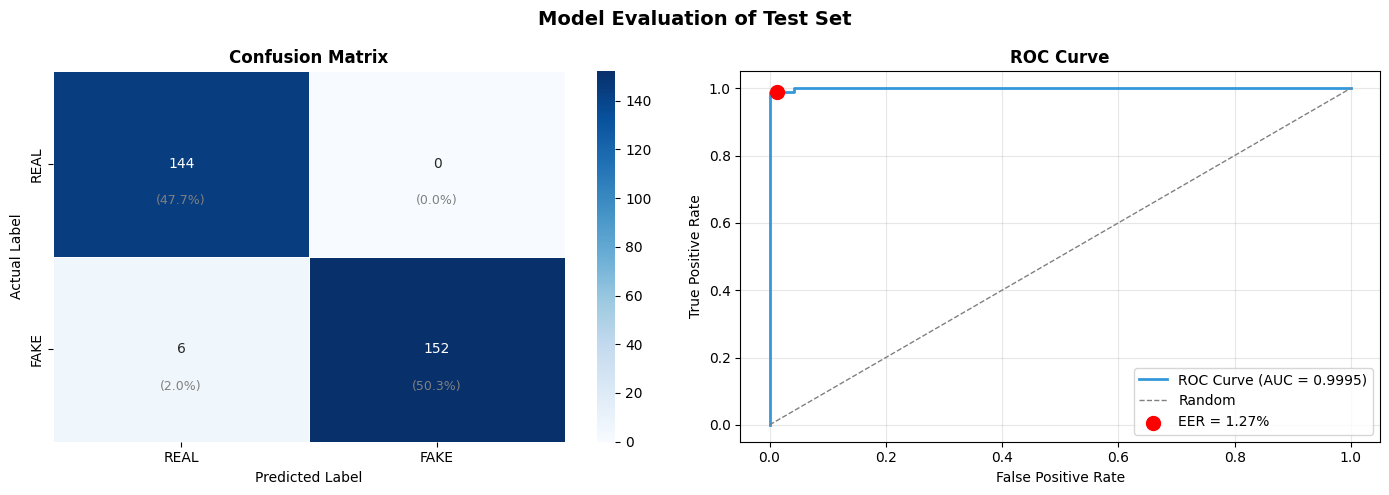

✅ Gambar disimpan!


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            ax=axes[0],
            xticklabels=['REAL', 'FAKE'],
            yticklabels=['REAL', 'FAKE'],
            linewidths=0.5)
axes[0].set_title('Confusion Matrix',
                   fontweight='bold', fontsize=12)
axes[0].set_ylabel('Actual Label')
axes[0].set_xlabel('Predicted Label')

total = len(y_test)
for i in range(2):
    for j in range(2):
        pct = cm[i,j] / total * 100
        axes[0].text(j+0.5, i+0.7, f'({pct:.1f}%)',
                     ha='center', va='center',
                     fontsize=9, color='gray')
        
axes[1].plot(fpr, tpr, color='#3498db', linewidth=2,
             label=f'ROC Curve (AUC = {auc_score:.4f})')
axes[1].plot([0,1], [0,1], color='gray',
             linewidth=1, linestyle='--', label='Random')
axes[1].scatter([eer], [1-eer], color='red', s=100,
                zorder=5, label=f'EER = {eer*100:.2f}%')
axes[1].set_title('ROC Curve',
                   fontweight='bold', fontsize=12)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Model Evaluation of Test Set',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Gambar disimpan!")